# Week 1 Assessment: HR Employee Analysis

This notebook explores employee data with NumPy and Pandas, cleans an intentionally imperfect dataset, compares departments, and saves four charts.

## Setup and project paths

The paths below work when the notebook kernel starts either in the project folder or in `notebooks/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "employees.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
CHARTS_DIR = PROJECT_ROOT / "reports" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)

Project folder: c:\Users\Dell\Desktop\Week1-Assessment


## 1. NumPy: student marks

Calculate student and subject averages, add five grace marks by broadcasting, then calculate weighted scores with `np.dot`.

In [2]:
marks = np.array(
    [
        [85, 90, 80],
        [75, 80, 85],
        [90, 95, 92],
        [60, 70, 65],
    ]
)

student_averages = marks.mean(axis=1)
subject_averages = marks.mean(axis=0)
graced_marks = marks + 5
weights = np.array([0.3, 0.3, 0.4])
weighted_scores = np.dot(graced_marks, weights)

print("Shape:", marks.shape)
print("Student averages:", student_averages)
print("Subject averages:", subject_averages)
print("Marks after 5 grace marks:\n", graced_marks)
print("Weighted scores after grace marks:", weighted_scores)

Shape: (4, 3)
Student averages: [85.         80.         92.33333333 65.        ]
Subject averages: [77.5  83.75 80.5 ]
Marks after 5 grace marks:
 [[ 90  95  85]
 [ 80  85  90]
 [ 95 100  97]
 [ 65  75  70]]
Weighted scores after grace marks: [89.5 85.5 97.3 70. ]


## 2. Load and explore employee data

Use Pandas `info`, `describe`, label-based and position-based selection, and a salary filter.

In [3]:
employees = pd.read_csv(DATA_DIR / "employees.csv")

employees.info()
display(employees.describe())

display(employees.loc[0:2, ["name", "salary"]])
display(employees.iloc[0:3, 0:3])
high_salary_employees = employees.loc[employees["salary"] > 50000]
display(high_salary_employees)

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes


,id,salary
count,8.00000,8.000000
mean,4.50000,58500.000000
std,2.44949,18913.336187
min,1.00000,30000.000000
25%,2.75000,47250.000000
50%,4.50000,56000.000000
75%,6.25000,69750.000000
max,8.00000,90000.000000


,name,salary
0,Arun,30000
1,Priya,45000
2,Rahul,60000


,id,name,department
0,1,Arun,Sales
1,2,Priya,HR
2,3,Rahul,IT


,id,name,department,salary,city
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Chennai


## 3. Timing a Pandas operation

Use the notebook `%timeit` magic once to time the mean salary calculation.

In [4]:
%timeit employees["salary"].mean()

41.3 μs ± 5.83 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## 4. Clean the employee data

The provided `employees_with_issues.csv` includes two missing salaries and one duplicate row. Drop duplicates, fill missing salaries with the median, and set numeric column types.

In [5]:
dirty_employees = pd.read_csv(DATA_DIR / "employees_with_issues.csv")
print("Missing salaries before cleaning:", dirty_employees["salary"].isna().sum())
print("Duplicate rows before cleaning:", dirty_employees.duplicated().sum())

cleaned_employees = dirty_employees.drop_duplicates().copy()
cleaned_employees["id"] = pd.to_numeric(
    cleaned_employees["id"], errors="raise"
).astype("int64")
cleaned_employees["salary"] = pd.to_numeric(
    cleaned_employees["salary"], errors="coerce"
)
median_salary = cleaned_employees["salary"].median()
cleaned_employees["salary"] = cleaned_employees["salary"].fillna(median_salary)
cleaned_employees["salary"] = cleaned_employees["salary"].astype("float64")

print("Median salary used for missing values:", median_salary)
display(cleaned_employees)

Missing salaries before cleaning: 2
Duplicate rows before cleaning: 1
Median salary used for missing values: 64000.0


,id,name,department,salary,city
0,1,Arun,Sales,64000.0,Chennai
1,2,Priya,HR,64000.0,Chennai
2,3,Rahul,IT,60000.0,Bangalore
3,4,Divya,IT,75000.0,Chennai
4,5,Karthik,Finance,90000.0,Mumbai
5,6,Meena,Sales,52000.0,Bangalore
6,7,Suresh,IT,68000.0,Chennai
7,8,Anitha,HR,48000.0,Mumbai


## 5. Department summary and joins

Aggregate headcount, average salary, and maximum salary. Compare employees with the department table using inner, left, and outer joins.

In [6]:
departments = pd.read_csv(DATA_DIR / "departments.csv")
department_order = ["Sales", "HR", "IT", "Finance"]

department_summary = (
    cleaned_employees.groupby("department")
    .agg(
        headcount=("id", "size"),
        average_salary=("salary", "mean"),
        maximum_salary=("salary", "max"),
    )
    .reindex(department_order)
    .reset_index()
)
display(department_summary)

inner_join = pd.merge(
    cleaned_employees, departments, on="department", how="inner"
)
left_join = pd.merge(
    cleaned_employees, departments, on="department", how="left"
)
outer_join = pd.merge(
    department_summary,
    departments,
    on="department",
    how="outer",
    indicator=True,
)

no_employee_departments = outer_join.loc[
    outer_join["_merge"] == "right_only", "department"
].tolist()
print("Rows in inner, left, and outer joins:", len(inner_join), len(left_join), len(outer_join))
print("Departments with no employees:", no_employee_departments)
display(outer_join)

,department,headcount,average_salary,maximum_salary
0,Sales,2,58000.000000,64000.0
1,HR,2,56000.000000,64000.0
2,IT,3,67666.666667,75000.0
3,Finance,1,90000.000000,90000.0


Rows in inner, left, and outer joins: 8 8 5
Departments with no employees: ['Legal']


,department,headcount,average_salary,maximum_salary,head,budget,_merge
0,Finance,1.0,90000.000000,90000.0,Finance Head,1500000,both
1,HR,2.0,56000.000000,64000.0,HR Head,500000,both
2,IT,3.0,67666.666667,75000.0,IT Head,2500000,both
3,Legal,NaN,NaN,NaN,Legal Head,400000,right_only
4,Sales,2.0,58000.000000,64000.0,Sales Head,1000000,both


## 6. Charts

Create a bar chart, histogram, scatter plot, and line chart. Each chart has a title, axis labels, and a legend; PNG files are saved in `reports/charts/`.

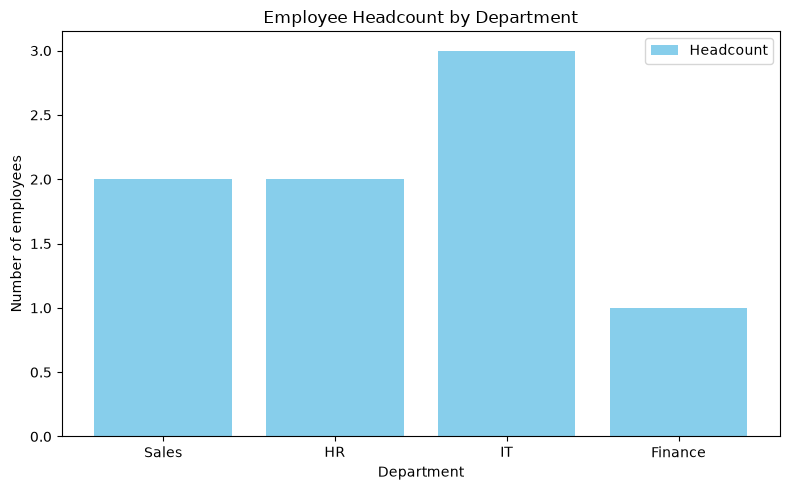

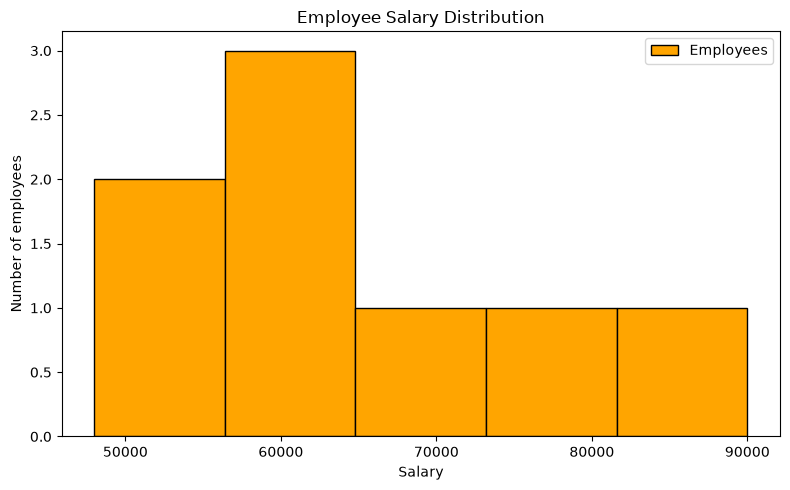

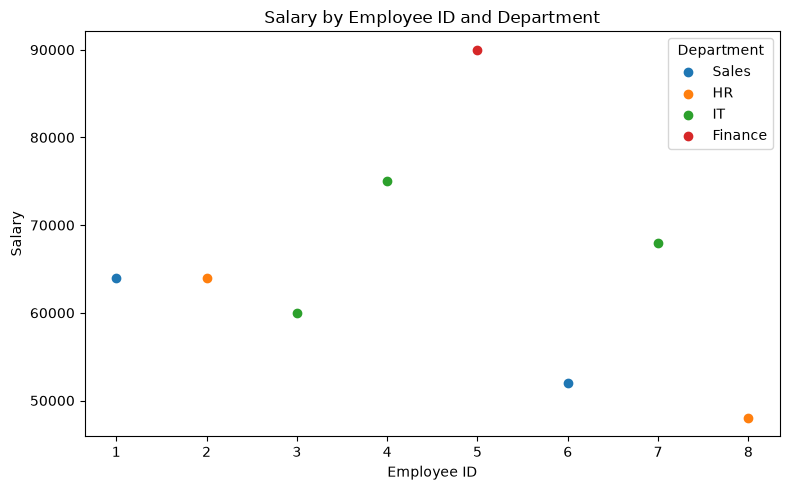

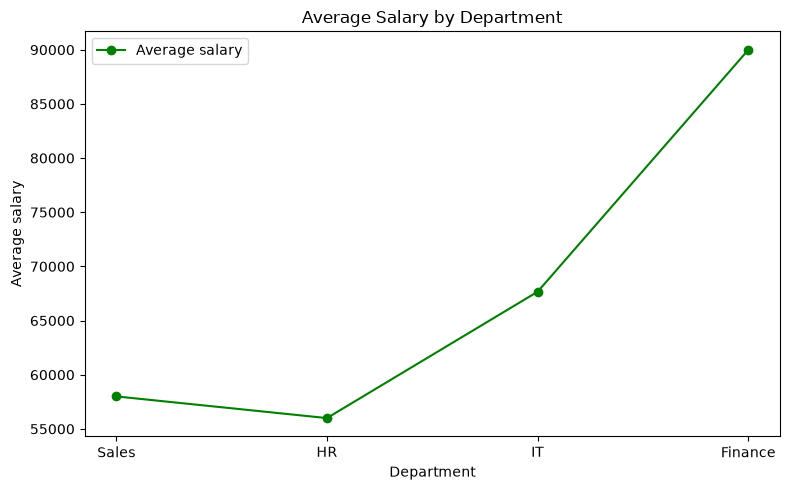

In [7]:
plt.figure(figsize=(8, 5))
plt.bar(
    department_summary["department"],
    department_summary["headcount"],
    color="skyblue",
    label="Headcount",
)
plt.title("Employee Headcount by Department")
plt.xlabel("Department")
plt.ylabel("Number of employees")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "department_headcount.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(
    cleaned_employees["salary"],
    bins=5,
    color="orange",
    edgecolor="black",
    label="Employees",
)
plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of employees")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "salary_distribution.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
for department in department_order:
    department_data = cleaned_employees.loc[
        cleaned_employees["department"] == department
    ]
    plt.scatter(
        department_data["id"],
        department_data["salary"],
        label=department,
    )
plt.title("Salary by Employee ID and Department")
plt.xlabel("Employee ID")
plt.ylabel("Salary")
plt.legend(title="Department")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "salary_vs_id.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    department_summary["department"],
    department_summary["average_salary"],
    marker="o",
    color="green",
    label="Average salary",
)
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average salary")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "average_salary_by_department.png", dpi=150)
plt.show()

## 7. Findings

- IT has the largest headcount, with three employees.
- Finance has the highest average and maximum salary in this dataset.
- The two missing salaries are filled with the median after the duplicate row is removed.
- Legal is listed in the department data but has no employees.

In [8]:
headcount_output = " | ".join(
    f"{row.department} {int(row.headcount)}"
    for row in department_summary.itertuples(index=False)
)

print("Student averages:", student_averages)
print("Headcount:", headcount_output)
print("Outer join: department with no employees listed")
for department in no_employee_departments:
    print(department)

Student averages: [85.         80.         92.33333333 65.        ]
Headcount: Sales 2 | HR 2 | IT 3 | Finance 1
Outer join: department with no employees listed
Legal
